```markdown
# Excited States Analysis

This Jupyter Notebook is dedicated to the analysis of excited states in a given solute-solvent system. The workflow involves parsing output files, extracting relevant data, and performing various analyses and visualizations.

## Workflow Overview

1. **Importing Libraries**: Essential libraries such as `pandas`, `re`, `matplotlib`, `seaborn`, and `numpy` are imported for data manipulation, parsing, and visualization.
2. **Setting Variables**: Variables like `solute`, `solvent`, and `file_path` are defined to specify the system and file locations.
3. **Parsing Output Files**: A function `parse_output` is defined to read and extract data from the output files.
4. **Data Aggregation**: Loop through the files, parse the data, and aggregate it into a DataFrame.
5. **Data Analysis**: Perform various analyses such as filtering, calculating statistics, and grouping data.
6. **Visualization**: Generate plots to visualize the data and results.

## Variables in Use

- **average_not_filtered_energy**: The mean energy for excited states that are not filtered.
- **ax**: The matplotlib axes object used for plotting.
- **data**: A list of dictionaries containing parsed data for a specific structure number.
- **data_list**: A list of dictionaries containing parsed data for all structure numbers.
- **df**: The main DataFrame containing all parsed data.
- **df_filtered**: A DataFrame containing filtered data based on specific criteria.
- **df_loaded**: The DataFrame loaded from a CSV file.
- **df_not_filtered**: A DataFrame containing data that is not filtered.
- **energy_filtered**: A Series containing filtered energy values.
- **energy_filtered_unique**: A Series containing unique filtered energy values.
- **file**: The file object for reading output files.
- **file_path**: The path to the directory containing output files.
- **filename**: The name of the current output file being processed.
- **filtered_df**: A DataFrame containing filtered data with energy above a certain threshold.
- **final_state**: The final state value for a specific transition.
- **grouped**: A DataFrame containing grouped data by structure number with mean and standard deviation of energy.
- **i**: An integer used in loops.
- **max_strength**: The maximum oscillator strength value.
- **mean_energy**: The mean energy value for a specific group.
- **min_strength**: The minimum oscillator strength value.
- **not_filtered_std_dev**: The standard deviation of energy for not filtered data.
- **output**: The content of the current output file being processed.
- **p**: A matplotlib patch object used in plotting.
- **solute**: The solute being analyzed.
- **solvent**: The solvent being analyzed.
- **state_std_devs**: A Series containing standard deviations of energy for each structure number.
- **struct_filtered**: A Series containing filtered structure numbers.
- **struct_filtered_unique**: A Series containing unique filtered structure numbers.
- **structure_number**: The current structure number being processed.
- **structure_numbers_filtered**: A Series containing filtered structure numbers.
- **total_average_energy**: The mean energy for all excited states.
- **total_std_dev**: The standard deviation of energy for all excited states.
- **unique_final_states**: A DataFrame containing unique final states for each structure number.
- **weighted_final_states**: A DataFrame containing final states with summed oscillator strengths and mean energy, normalized.

This notebook provides a comprehensive analysis of excited states, leveraging various data manipulation and visualization techniques to derive meaningful insights.
```

Excited states analysis

In [1]:
import pandas as pd
import re
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
# set solute, solvent and file path
solute = "pNA"
solvent = "cHex"
nn = "14"

#file_path = f"{solvent}/excited_states"
file_path = f"fixed_number_neighbor/{solvent}/excited_states"

# Conversion factor: 1 Hartree = 627.5095 kcal/mol
HA_TO_KCAL_MOL = 627.5095

data_list = []

In [3]:
# Read the file and parse the output
def parse_output(output, structure_number):
    lines = output.strip().split('\n')
    excited_states = []
    current_state = None
    scf_energy = None
    
    for line in lines:
        # Match SCF energy
        scf_match = re.search(r'SCF Done:\s+E\([\w]+\)\s+=\s+([-.\d]+)', line)
        if scf_match:
            scf_energy = float(scf_match.group(1))
            continue

        # Match Excited State
        match = re.match(r' Excited State\s+(\d+):\s+(\w+)-A\s+([\d.]+)\s+eV\s+([\d.]+)\s+nm\s+f=([\d.]+)\s+\<S\*\*\d+\>=([\d.]+)', line)
        if match:
            state_number = int(match.group(1))
            energy = float(match.group(3))
            strength = float(match.group(5))
            transitions = []
            current_state = (state_number, energy, strength, transitions)
            excited_states.append(current_state)
        
        # Match Transitions
        transition_match = re.match(r'\s+(\d+)\s+->\s+(\d+)\s+([\d.-]+)', line)
        if transition_match is None:
            transition_match = re.match(r'\s+(\d+)\s+->(\d+)\s+([\d.-]+)', line)
        if transition_match and current_state:
            transition_from = int(transition_match.group(1))
            transition_to = int(transition_match.group(2))
            contribution = float(transition_match.group(3))
            current_state[3].append((transition_from, transition_to, contribution))
    
    data = []
    
    # Get the strongest excited state
    if excited_states:
        strongest_state = max(excited_states, key=lambda x: x[2])

        # Add data for the strongest state
        for t in strongest_state[3]:
            # Convert SCF Energy from Ha to kcal/mol
            scf_energy_kcal = scf_energy * HA_TO_KCAL_MOL if scf_energy is not None else None

            data.append({
                'Structure Number': structure_number,
                'Excited State Number': strongest_state[0],
                'Energy (eV)': strongest_state[1],
                'Strength (f)': strongest_state[2],
                'Initial state': t[0],
                'Final state': t[1],
                'Contribution': t[2],
                'SCF Energy (Ha)': scf_energy,
                'SCF Energy (kcal/mol)': scf_energy_kcal
            })
    # If no excited states are found, return a row with None values
    else:
        scf_energy_kcal = scf_energy * HA_TO_KCAL_MOL if scf_energy is not None else None
        data.append({
            'Structure Number': structure_number,
            'Excited State Number': None,
            'Energy (eV)': None,
            'Strength (f)': None,
            'Initial state': None,
            'Final state': None,
            'Contribution': None,
            'SCF Energy (Ha)': scf_energy,
            'SCF Energy (kcal/mol)': scf_energy_kcal
        })
    
    return data

In [4]:
# loop through the files and parse the data
# adjust the range to match the number of files
for structure_number in range(50, 2501, 50):
    filename = f"{file_path}/{solute}_{nn}{solvent}_frame_{structure_number}.out"
    with open(filename, 'r') as file:
        output = file.read()
    
    data = parse_output(output, structure_number)
    data_list.extend(data)

# create a *DataFrame* from the list of dictionaries
df = pd.DataFrame(data_list)

# delete the existing CSV file if it exists
csv_file_path = f"{file_path}/excited_states_data.csv"
if os.path.exists(csv_file_path):
    os.remove(csv_file_path)

# save the DataFrame to a new CSV file
df.to_csv(csv_file_path, index=False)

# load the DataFrame from the CSV file
df_loaded = pd.read_csv(csv_file_path)

# display the loaded DataFrame
print(df_loaded)

FileNotFoundError: [Errno 2] No such file or directory: 'fixed_number_neighbor/cHex/excited_states/pNA_14cHex_frame_50.out'

In [92]:
# display the columns of the loaded DataFrame
print(df_loaded.columns)

Index(['Structure Number', 'Excited State Number', 'Energy (eV)',
       'Strength (f)', 'Initial state', 'Final state', 'Contribution',
       'SCF Energy (Ha)', 'SCF Energy (kcal/mol)'],
      dtype='object')


In [96]:
# display the data corresponding to the structure number 50
# df_loaded[df_loaded['Structure Number'] == 50]
# display the data in column 'Final state'
# df_loaded['Final state']

# sort the DataFrame by the column 'SCF Energy (kcal/mol)'
df_loaded.sort_values('SCF Energy (kcal/mol)')

,Structure Number,Excited State Number,Energy (eV),Strength (f),Initial state,Final state,Contribution,SCF Energy (Ha),SCF Energy (kcal/mol)
65,1250,1,3.7116,0.2725,372,373,0.67874,-3794.318359,-2.380971e+06
64,1250,1,3.7116,0.2725,360,373,0.11233,-3794.318359,-2.380971e+06
0,50,1,3.6171,0.2426,351,373,-0.17311,-3794.315890,-2.380969e+06
1,50,1,3.6171,0.2426,372,373,0.66799,-3794.315890,-2.380969e+06
41,800,2,3.8010,0.2635,372,373,0.67804,-3794.315301,-2.380969e+06
...,...,...,...,...,...,...,...,...,...
70,1350,2,3.8011,0.1426,367,373,0.18171,-3794.238760,-2.380921e+06
69,1350,2,3.8011,0.1426,359,373,-0.11239,-3794.238760,-2.380921e+06
68,1350,2,3.8011,0.1426,348,373,-0.20695,-3794.238760,-2.380921e+06
67,1350,2,3.8011,0.1426,347,373,-0.35766,-3794.238760,-2.380921e+06


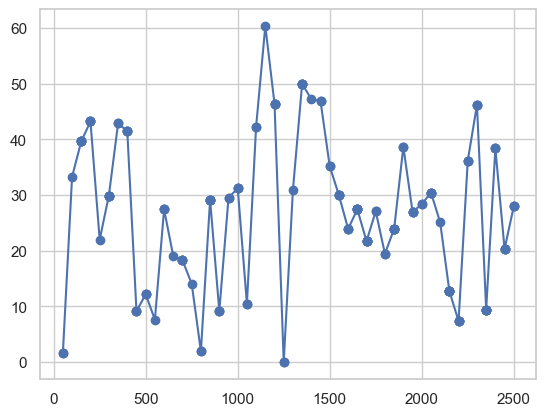

In [109]:
# plot 'SCF Energy (kcal/mol)' vs 'Structure Number'
plt.figure()
plt.plot(df_loaded['Structure Number'], df_loaded['SCF Energy (kcal/mol)'], 'o-')

     Structure Number  SCF Energy (kcal/mol)
0                  50               1.549007
1                  50               1.549007
2                 100              33.253052
3                 150              39.644776
4                 150              39.644776
..                ...                    ...
148              2450              20.299236
149              2450              20.299236
150              2500              27.957494
151              2500              27.957494
152              2500              27.957494

[153 rows x 2 columns]


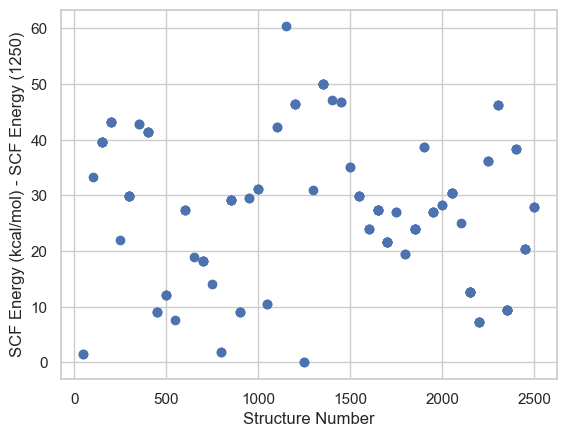

In [108]:
# Find the SCF Energy (kcal/mol) of Structure Number 1250
scf_energy_1250 = df_loaded.loc[df_loaded['Structure Number'] == 1250, 'SCF Energy (kcal/mol)'].values[0]

# Subtract SCF Energy of structure number 1250 from all other SCF Energy values
df_loaded['SCF Energy (kcal/mol)'] = df_loaded['SCF Energy (kcal/mol)'] - scf_energy_1250

# Print the adjusted values for all rows
print(df_loaded[['Structure Number', 'SCF Energy (kcal/mol)']])

# Now plot the data
plt.plot(df_loaded['Structure Number'], df_loaded['SCF Energy (kcal/mol)'], 'o')
plt.xlabel('Structure Number')
plt.ylabel('SCF Energy (kcal/mol) - SCF Energy (1250)')
plt.show()

In [83]:
# display the data corresponding to the 'Final state' 373
df_loaded[df_loaded['Final state'] == 373]
df_loaded['Final state'].value_counts()

Final state
373    150
374      1
375      1
376      1
Name: count, dtype: int64

In [95]:
# filter the data which excited state is either 1 or 2
# let's see is there is anything left
df_filtered = df_loaded[(df_loaded['Excited State Number'] != 1) & (df_loaded['Excited State Number'] != 2)]
print(df_filtered)

    Structure Number  Excited State Number  Energy (eV)  Strength (f)  \
60              1200                    30       5.2961        0.1169   
61              1200                    30       5.2961        0.1169   
62              1200                    30       5.2961        0.1169   
63              1200                    30       5.2961        0.1169   

    Initial state  Final state  Contribution  SCF Energy (Ha)  \
60            342          373       0.11234     -3794.244454   
61            370          374       0.11528     -3794.244454   
62            372          375       0.58984     -3794.244454   
63            372          376      -0.28275     -3794.244454   

    SCF Energy (kcal/mol)  
60          -2.380924e+06  
61          -2.380924e+06  
62          -2.380924e+06  
63          -2.380924e+06  


In [ ]:
# drop the duplicates: keep only the unique values in terms of 'Structure Number'
struct_filtered = df_filtered['Structure Number']
struct_filtered_unique = struct_filtered.drop_duplicates()
print(struct_filtered_unique)

60    1200
Name: Structure Number, dtype: int64


In [ ]:
# and print their energy
energy_filtered = df_filtered['Energy (eV)']
energy_filtered_unique = energy_filtered.drop_duplicates()
print(energy_filtered_unique)

60    5.2961
Name: Energy (eV), dtype: float64


In [31]:
# statistics for the energy of the excited states

# mean energy for all excited states
total_average_energy = df['Energy (eV)'].mean()
# mean energy for excited states that are 1 or 2
filtered_average_energy = df[~df.index.isin(df_filtered.index)]['Energy (eV)'].mean()

# standard deviation for the total energy
total_std_dev = df['Energy (eV)'].std()
# standard deviation for excited states that are 1 or 2
filtered_std_dev = df[~df.index.isin(df_filtered.index)]['Energy (eV)'].std()

print(f"Total Average Energy: {total_average_energy}")
print(f"Average Filtered Energy: {filtered_average_energy}")
print(f"Total Standard Deviation: {total_std_dev}")
print(f"Filtered Standard Deviation: {filtered_std_dev}")

Total Average Energy: 3.7188712418300653
Average Filtered Energy: 3.676529530201342
Total Standard Deviation: 0.3072720001273522
Filtered Standard Deviation: 0.16712012167306797


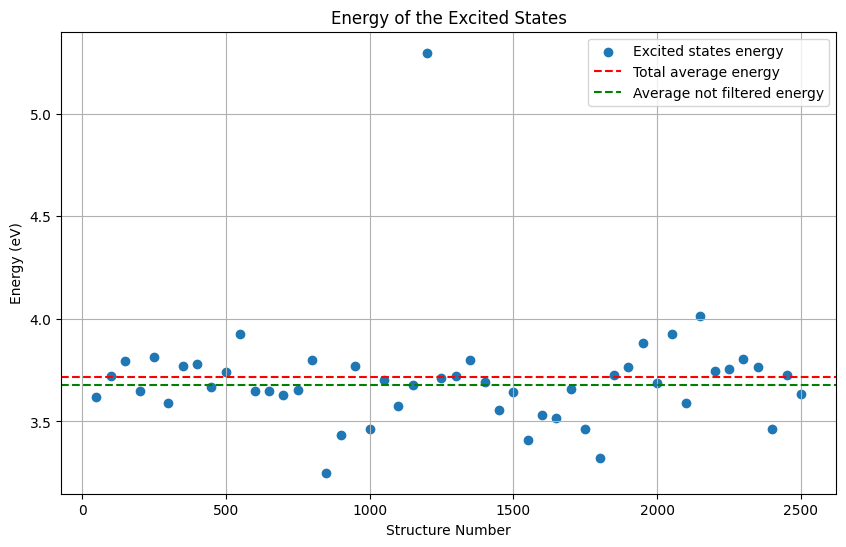

In [33]:
grouped = df.groupby('Structure Number')['Energy (eV)'].agg(['mean', 'std']).reset_index()

plt.figure(figsize=(10, 6))
plt.scatter(grouped['Structure Number'], grouped['mean'], label='Excited states energy')
plt.axhline(total_average_energy, color='red', linestyle='--', label='Total average energy')
plt.axhline(filtered_average_energy, color='green', linestyle='--', label='Average not filtered energy')

plt.xlabel('Structure Number')
plt.ylabel('Energy (eV)')
plt.title('Energy of the Excited States')
plt.legend()
plt.grid(True)
plt.show()

In [15]:
# Filter the DataFrame for elements with energy above 4.5 eV
filtered_df = df[df['Energy (eV)'] > 4.5]
# drop duplicates
filtered_df = filtered_df.drop_duplicates(subset=['Structure Number'])

# Print the structure numbers of these elements
print(filtered_df['Structure Number'])

60    1200
Name: Structure Number, dtype: int64


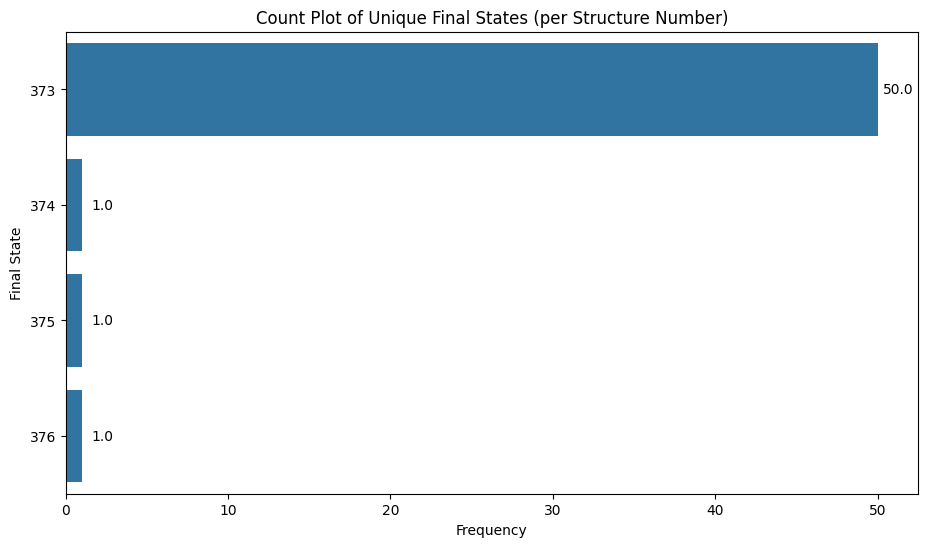

In [34]:
# histogram plot to show the distribution of the 'Energy (eV)' column

# drop duplicate 'Final state' values for each 'Structure Number'
unique_final_states = df_loaded.drop_duplicates(subset=['Structure Number', 'Final state'])

# histogram plot of the 'Final state' column
plt.figure(figsize=(11, 6))
ax = sns.countplot(y=unique_final_states['Final state'], order=unique_final_states['Final state'].value_counts().index)
plt.title('Count Plot of Unique Final States (per Structure Number)')
plt.xlabel('Frequency')
plt.ylabel('Final State')

# annotate the counts on top of each bar
for p in ax.patches:
    ax.annotate(f'{p.get_width()}', 
                (p.get_width(), p.get_y() + p.get_height() / 2), 
                ha='center', va='center', 
                fontsize=10, color='black', 
                xytext=(15, 0),
                textcoords='offset points')

plt.show()

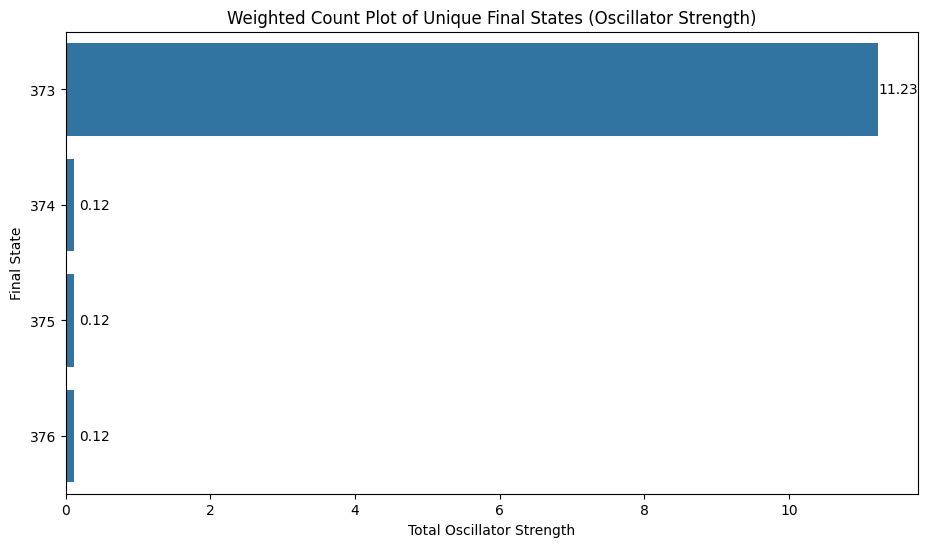

In [ ]:
# histogram plot to show the distribution of the 'Energy (eV)' column, weighted by the 'Strength (f)' column

# drop duplicate 'Final state' values for each 'Structure Number' and keep the associated oscillator strengths
unique_final_states = df_loaded.drop_duplicates(subset=['Structure Number', 'Final state'])

# group by 'Final state' and sum the oscillator strengths
weighted_final_states = unique_final_states.groupby('Final state', as_index=False).agg({'Strength (f)': 'sum'})

# sort by total oscillator strength in descending order
weighted_final_states = weighted_final_states.sort_values(by='Strength (f)', ascending=False)

# create the horizontal bar plot
plt.figure(figsize=(11, 6))
ax = sns.barplot(x='Strength (f)', y='Final state', data=weighted_final_states, orient='h', order=weighted_final_states['Final state'].value_counts().index)
plt.title('Weighted Count Plot of Unique Final States (Oscillator Strength)')
plt.xlabel('Total Oscillator Strength')
plt.ylabel('Final State')

# annotate the sums on top of each bar
for p in ax.patches:
    ax.annotate(f'{p.get_width():.2f}', 
                (p.get_width(), p.get_y() + p.get_height() / 2), 
                ha='center', va='center', 
                fontsize=10, color='black', 
                xytext=(15, 0),
                textcoords='offset points')

plt.show()

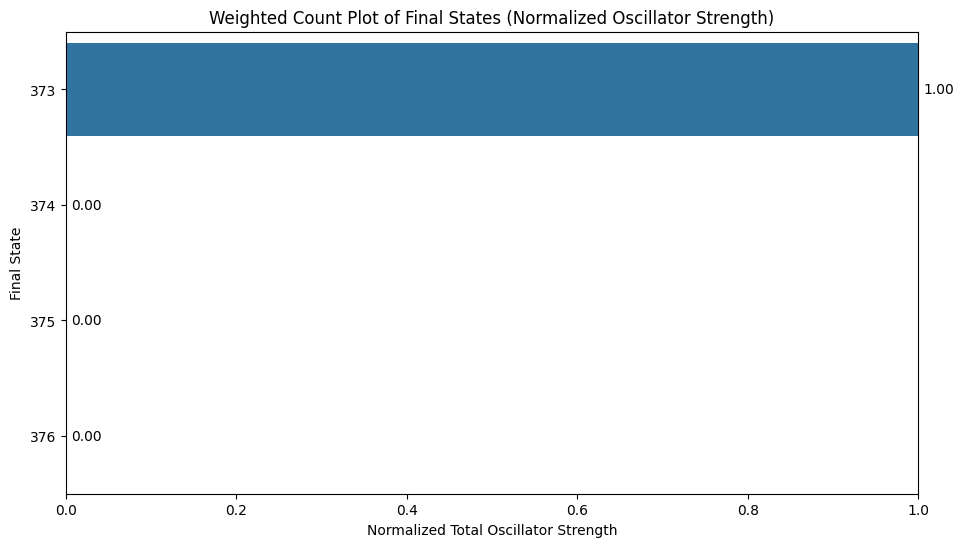

In [ ]:

# histogram plot to show the distribution of the 'Energy (eV)' column, weighted by the 'Strength (f)' column and normalized

# drop duplicate 'Final state' values for each 'Structure Number' and keep the associated oscillator strengths
unique_final_states = df_loaded.drop_duplicates(subset=['Structure Number', 'Final state'])

# group by 'Final state' and sum the oscillator strengths
weighted_final_states = unique_final_states.groupby('Final state', as_index=False).agg({'Strength (f)': 'sum'})

# normalize the oscillator strengths to range from 0 to 1
min_strength = weighted_final_states['Strength (f)'].min()
max_strength = weighted_final_states['Strength (f)'].max()
weighted_final_states['Normalized Strength (f)'] = (weighted_final_states['Strength (f)'] - min_strength) / (max_strength - min_strength)

# sort by normalized oscillator strength in descending order
weighted_final_states = weighted_final_states.sort_values(by='Normalized Strength (f)', ascending=False)

# create the horizontal bar plot
plt.figure(figsize=(11, 6))
ax = sns.barplot(x='Normalized Strength (f)', y='Final state', data=weighted_final_states, orient='h', order=weighted_final_states['Final state'])
plt.title('Weighted Count Plot of Final States (Normalized Oscillator Strength)')
plt.xlabel('Normalized Total Oscillator Strength')
plt.ylabel('Final State')

# annotate the sums on top of each bar
for p in ax.patches:
    ax.annotate(f'{p.get_width():.2f}', 
                (p.get_width(), p.get_y() + p.get_height() / 2), 
                ha='center', va='center', 
                fontsize=10, color='black', 
                xytext=(15, 0),
                textcoords='offset points')

# Set x-axis limits to [0, 1]
plt.xlim(0, 1)
plt.show()

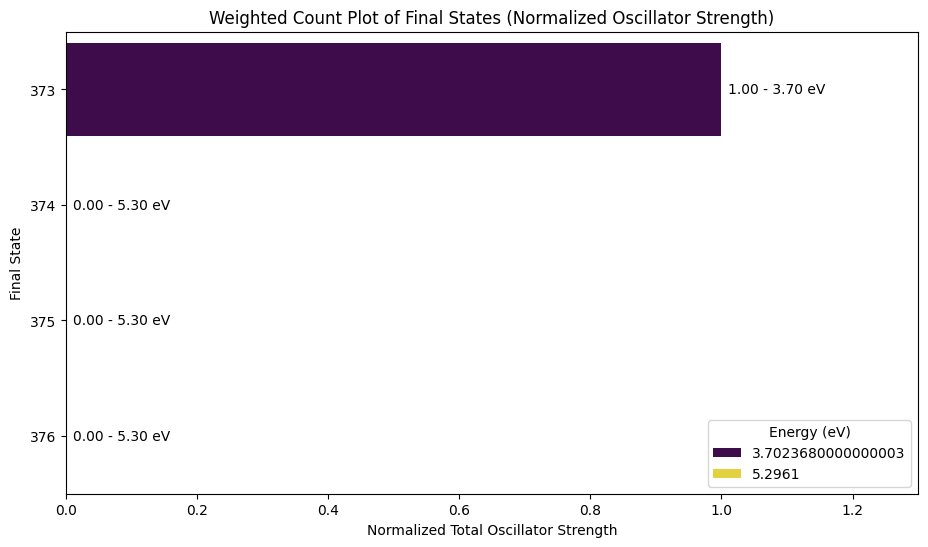

In [ ]:
# histogram plot to show the distribution of the 'Energy (eV)' column, weighted by the 'Strength (f)' column and normalized
# with the mean energy of each 'Final state' as a hue

# Drop duplicate 'Final state' values for each 'Structure Number' and keep associated oscillator strengths
unique_final_states = df_loaded.drop_duplicates(subset=['Structure Number', 'Final state'])

# Group by 'Final state', sum the oscillator strengths, and calculate the mean energy
weighted_final_states = unique_final_states.groupby('Final state', as_index=False).agg({'Strength (f)': 'sum', 'Energy (eV)': 'mean'})

# Normalize the oscillator strengths to range from 0 to 1
min_strength = weighted_final_states['Strength (f)'].min()
max_strength = weighted_final_states['Strength (f)'].max()
weighted_final_states['Normalized Strength (f)'] = (weighted_final_states['Strength (f)'] - min_strength) / (max_strength - min_strength)

# Sort by normalized oscillator strength in descending order
weighted_final_states = weighted_final_states.sort_values(by='Normalized Strength (f)', ascending=False)

# Create the horizontal bar plot
plt.figure(figsize=(11, 6))
ax = sns.barplot(x='Normalized Strength (f)',
                 y='Final state', 
                 data=weighted_final_states, 
                 orient='h', 
                 order=weighted_final_states['Final state'].tolist(), 
                 palette='viridis', 
                 hue='Energy (eV)')

plt.title('Weighted Count Plot of Final States (Normalized Oscillator Strength)')
plt.xlabel('Normalized Total Oscillator Strength')
plt.ylabel('Final State')

# Annotate the sums on top of each bar and the mean energy
for i, p in enumerate(ax.patches):
    if i < len(weighted_final_states):
        # Get the final state corresponding to this patch
        final_state = weighted_final_states.iloc[i]['Final state']
        # Get the mean energy of this final state
        mean_energy = weighted_final_states.iloc[i]['Energy (eV)']
        # Annotate the normalized strength
        ax.annotate(f'{p.get_width():.2f} - {mean_energy:.2f} eV', 
                    (p.get_width(), p.get_y() + p.get_height() / 2), 
                    ha='center', va='center', 
                    fontsize=10, color='black', 
                    xytext=(40, 0),
                    textcoords='offset points')

# Set x-axis limits to [0, 1]
plt.xlim(0, 1.3)
plt.show()